# Cognitive workload come mediatore: confirmshaming e preselected options

**Research question (originale).** *To what extent does cognitive workload (specifically NASA-TLX mental demand, temporal demand, and frustration) mediate the relationship between confirmshaming interface design and immediate promotional offer acceptance (task compliance) in e-commerce checkout flows?*

**Estensione.** Il notebook analizza anche la condizione con **preselected options**. Le tre condizioni sono:

| Valore in `condition` | Significato (assunto) |
|---|---|
| `condition_v1` | baseline / controllo (**gruppo di riferimento**) |
| `condition_v2` | confirmshaming |
| `condition_v3` | preselected options |

> **Verifica l'assunzione su v1.** Se la baseline non è v1, cambia `REFERENCE` nella cella di configurazione.

**Modello.** X multicategorica con *dummy coding* rispetto alla baseline (D2 = v2, D3 = v3) → M = carico cognitivo (un mediatore alla volta) → Y = `acceptance` (0/1). Si stimano gli **effetti indiretti relativi** (Hayes & Preacher, 2014): per ogni trattamento j, a_j × b, dove a_j è la differenza del mediatore tra il trattamento j e la baseline e b è l'effetto del mediatore sull'accettazione, a parità di condizione. In più si confronta direttamente v3 con v2: (a₃ − a₂) × b.

**Scelte metodologiche (campione molto piccolo):**
- tre mediatori testati **separatamente**, più un indice composito;
- Y binaria → regressione logistica con penalizzazione di **Firth** (robusta alla separazione perfetta); effetto indiretto in **log-odds**, mediatore in unità di SD;
- inferenza con **bootstrap percentile stratificato per condizione**, non con Baron & Kenny né Sobel;
- analisi da dichiarare **esplorativa**: con 3 gruppi e circa 25 casi con NASA-TLX ci sono pochissime osservazioni per gruppo.

**Indice**
1. Configurazione e caricamento
2. Pulizia dei dati e codifica delle condizioni
3. Dati mancanti
4. Statistiche descrittive
5. Affidabilità dei mediatori e indice composito
6. Effetti totali sull'accettazione
7. Analisi di mediazione
8. Grafici
9. Sintesi dei risultati e limiti


IMPORTANTE! per ora non sto leggendo i csv veri, solo il risultato creato dall'altro file

## 1. Configurazione e caricamento

In [48]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# ---------------- CONFIGURAZIONE ----------------
DATA_PATH = "Deciptive_Design_Analysis/test.csv"              # percorso del file (.csv o .xlsx)
CONDITION_COL = "condition"         # colonna con v1_condition / v2 / v3
REFERENCE = "v1_condition"          # gruppo di riferimento (baseline)
TREATMENTS = {                      # valore in CONDITION_COL -> etichetta
    "v2_condition": "Confirmshaming",
    "v3_condition": "Preselected options",
}
REFERENCE_LABEL = "Baseline"
Y_COL = "acceptance"                # esito: 1 = offerta accettata, 0 = rifiutata
MEDIATORS = {
    "nasa_mental_demand": "Mental demand",
    "nasa_temporal_demand": "Temporal demand",
    "nasa_frustration": "Frustration",
}
N_BOOT = 5000                       # ricampionamenti bootstrap
N_PERM = 5000                       # permutazioni per i test chi-quadro
SEED = 2026
ALPHA = 0.05
STANDARDIZE_M = True                # mediatore in unità di deviazione standard
# ------------------------------------------------

assert len(TREATMENTS) == 2, "Il notebook è scritto per 1 baseline + 2 trattamenti"
rng = np.random.default_rng(SEED)

In [49]:
if DATA_PATH.lower().endswith((".xlsx", ".xls")):
    raw = pd.read_excel(DATA_PATH)
else:
    raw = pd.read_csv(DATA_PATH)

print("Dimensioni:", raw.shape)
raw.info()
raw.head()

Dimensioni: (33, 20)
<class 'pandas.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   timestamp                 33 non-null     str    
 1   participant_id            33 non-null     str    
 2   condition                 33 non-null     str    
 3   action_taken              33 non-null     str    
 4   deliberation_time_sec     33 non-null     float64
 5   email_entered             33 non-null     bool   
 6   checkboxes_checked        33 non-null     str    
 7   nasa_mental_demand        25 non-null     float64
 8   nasa_temporal_demand      25 non-null     float64
 9   nasa_effort               24 non-null     float64
 10  nasa_frustration          25 non-null     float64
 11  willingness_to_recommend  25 non-null     float64
 12  age_group                 31 non-null     str    
 13  device_type               31 non-null     str    
 14  pu

,timestamp,participant_id,condition,action_taken,deliberation_time_sec,email_entered,checkboxes_checked,nasa_mental_demand,nasa_temporal_demand,nasa_effort,nasa_frustration,willingness_to_recommend,age_group,device_type,purchase_frequency,computer_usage,pressure_perception,sarcastic_mocking_extent,have_read_popup,acceptance
0,2026-11-11T10:29:59.876Z,P_9FKETYLM,v1_condition,clicked_close_x_button,3.80,False,none,1.0,1.0,1.0,1.0,4.0,22-26,Smartphone,A couple of times per month,More than 8 hours,4.0,1.0,NaN,0
1,2026-11-11T13:28:59.899Z,P_8S0L2MHA,v2_condition,clicked_decline_text_link,2.01,False,2/2 checked,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,3.0,Yes,0
2,2026-11-11T13:33:20.565Z,P_CMQ6YXJ9,v1_condition,clicked_submit_decline,3.28,False,none,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,1.0,Yes,0
3,2026-11-12T16:24:09.035Z,P_BQ2TDYO7,v1_condition,clicked_submit_decline,2.17,False,none,NaN,NaN,NaN,NaN,NaN,18-21,Computer / Laptop,Less than once per month,More than 8 hours,NaN,NaN,No,0
4,2026-11-12T16:28:57.013Z,P_IJFECCH8,v3_condition,clicked_submit_accept,54.11,True,none,8.0,3.0,5.0,6.0,4.0,18-21,Smartphone,A couple of times per month,More than 8 hours,5.0,6.0,Yes,1


## 2. Pulizia dei dati e codifica delle condizioni

In [50]:
df = raw.copy()

# 2) duplicati di participant_id (si tiene la prima risposta in ordine temporale)#TODO: Will be changed with the config in the old file
df = df.sort_values("timestamp")
n_dup = int(df["participant_id"].duplicated().sum())
print(f"Duplicati di participant_id esclusi: {n_dup}")
df = df[~df["participant_id"].duplicated()].copy()

# 3) condizioni
# 3a. Mostrare cosa c'è
print("\nValori di", CONDITION_COL)
print(df[CONDITION_COL].value_counts(dropna=False))
# 3b. Verificare che ci siano tutte le condizioni attese
expected = [REFERENCE] + list(TREATMENTS)
present = set(df[CONDITION_COL].dropna().unique())
absent = [l for l in expected if l not in present]
if absent:
    raise ValueError(f"Livelli attesi non trovati in '{CONDITION_COL}': {absent}. Presenti: {sorted(present)}")
# 3c. Gestire valori inattesi
extra = present - set(expected)
if extra:
    print(f"\nATTENZIONE: livelli non previsti, righe escluse: {sorted(extra)}")
    df = df[df[CONDITION_COL].isin(expected)].copy()

# 3d. Dare nomi leggibili
LABELS = {REFERENCE: REFERENCE_LABEL, **TREATMENTS}
cond_order = [LABELS[k] for k in expected]
df["cond"] = pd.Categorical(df[CONDITION_COL].map(LABELS), categories=cond_order, ordered=True)

# 3e. Creare le dummy
# dummy coding rispetto alla baseline: D_condition_v2 = 1 se confirmshaming , D_condition_v2 = 1 se Preselected options
# (calcoli statistici hanno bisogno di avere le dummy ovvero valori numerici su cui lavorare)
TREAT_KEYS = list(TREATMENTS)
D_COLS = []
for k in TREAT_KEYS:
    col = f"D_{k}"
    df[col] = (df[CONDITION_COL] == k).astype(int)
    D_COLS.append(col)
print(f"\nCodifica: baseline = '{REFERENCE}'; dummy = {D_COLS}")

# 4) setup per l'esito Y
df["Y"] = pd.to_numeric(df[Y_COL], errors="coerce").astype(float)
assert set(df["Y"].dropna().unique()) <= {0.0, 1.0}, "acceptance deve essere 0/1"
print("\nCoerenza acceptance vs action_taken, per condizione")
print("(controlla che 'acceptance' abbia lo stesso significato nelle tre condizioni, in particolare in v3):")
print(pd.crosstab([df["cond"], df["action_taken"]], df["Y"]))

# 5) mediatori numerici
for c in MEDIATORS:
    df[c] = pd.to_numeric(df[c], errors="coerce")
print("\nRange dei mediatori (controlla la scala NASA-TLX, es. 0-100 o 1-21):")
df[list(MEDIATORS)].describe().loc[["count", "min", "max"]]

Duplicati di participant_id esclusi: 1

Valori di condition
condition
v1_condition    14
v3_condition    11
v2_condition     7
Name: count, dtype: int64

Codifica: baseline = 'v1_condition'; dummy = ['D_v2_condition', 'D_v3_condition']

Coerenza acceptance vs action_taken, per condizione
(controlla che 'acceptance' abbia lo stesso significato nelle tre condizioni, in particolare in v3):
Y                                              0.0  1.0
cond                action_taken                       
Baseline            clicked_close_x_button       1    0
                    clicked_submit_decline      13    0
Confirmshaming      clicked_decline_text_link    5    0
                    clicked_submit_accept        0    2
Preselected options clicked_decline_text_link    8    0
                    clicked_submit_accept        0    3

Range dei mediatori (controlla la scala NASA-TLX, es. 0-100 o 1-21):


,nasa_mental_demand,nasa_temporal_demand,nasa_frustration
count,24.0,24.0,24.0
min,1.0,1.0,1.0
max,9.0,10.0,10.0


## 3. Dati mancanti

All'inizio della fase di testing la compilazione delle dimensioni NASA-TLX selezionate nel questionario non era obbligatoria; è stata resa obbligatoria in seguito per raccogliere più dati, visto il numero ridotto di partecipanti. Per questo, alcuni punteggi NASA-TLX mancano.

Osservando i dati è nata un'ipotesi: chi non ha risposto potrebbe non essere un gruppo "casuale". Ad esempio, qualcuno potrebbe aver accelerato il processo a causa dello stress provocato dalla condizione che ha visto. Controlliamo due cose:
1. i mancanti sono distribuiti in modo simile nelle tre condizioni?
2. chi non ha risposto ha impiegato meno tempo a decidere (`deliberation_time_sec`) di chi ha risposto?

In [51]:
med_cols = list(MEDIATORS)
df["nasa_missing"] = df[med_cols].isna().any(axis=1)   # True = almeno un punteggio NASA-TLX manca

# 1) i mancanti sono distribuiti in modo simile tra le condizioni?
miss_cond = df.groupby("cond", observed=True)["nasa_missing"].agg(n="size", mancanti="sum", percentuale="mean")
miss_cond["percentuale"] = (miss_cond["percentuale"] * 100).round(0)
print("Mancanti NASA-TLX per condizione:")
print(miss_cond)

# 2) chi non ha risposto ha deciso più in fretta?
t_ok = df.loc[~df["nasa_missing"], "deliberation_time_sec"].dropna()
t_miss = df.loc[df["nasa_missing"], "deliberation_time_sec"].dropna()
print("\nTempo di deliberazione (secondi):")
print(f"  hanno risposto      (n = {len(t_ok)}):   mediana = {t_ok.median():.1f}")
print(f"  non hanno risposto  (n = {len(t_miss)}):   mediana = {t_miss.median():.1f}")
if len(t_ok) > 0 and len(t_miss) > 0:
    p_t = stats.mannwhitneyu(t_miss, t_ok, alternative="two-sided").pvalue
    print(f"  Test di Mann-Whitney: p = {p_t:.3f}")

Mancanti NASA-TLX per condizione:
                      n  mancanti  percentuale
cond                                          
Baseline             14         4         29.0
Confirmshaming        7         1         14.0
Preselected options  11         3         27.0

Tempo di deliberazione (secondi):
  hanno risposto      (n = 24):   mediana = 9.3
  non hanno risposto  (n = 8):   mediana = 10.4
  Test di Mann-Whitney: p = 0.428


## 4. Statistiche descrittive

In [52]:
desc = df.groupby("cond", observed=True).agg(
    n=("Y", "size"),
    accettazione_media=("Y", "mean"),
    **{f"{c}_media": (c, "mean") for c in med_cols},
    **{f"{c}_sd": (c, "std") for c in med_cols},
    **{f"{c}_n": (c, "count") for c in med_cols},
).T
desc.round(2)

cond,Baseline,Confirmshaming,Preselected options
n,14.00,7.00,11.00
accettazione_media,0.00,0.29,0.27
nasa_mental_demand_media,3.50,4.00,4.38
nasa_temporal_demand_media,3.20,4.67,5.12
nasa_frustration_media,4.80,4.00,4.50
nasa_mental_demand_sd,1.78,3.29,1.77
nasa_temporal_demand_sd,2.20,3.67,2.59
nasa_frustration_sd,3.12,3.03,2.67
nasa_mental_demand_n,10.00,6.00,8.00
nasa_temporal_demand_n,10.00,6.00,8.00


## 5. Affidabilità dei mediatori e indice composito

Si valuta se i tre mediatori sono abbastanza correlati da poter essere sintetizzati in un indice unico di carico cognitivo. Se l'alpha di Cronbach è basso (indicativamente sotto 0,6) l'indice composito non è giustificato: tieni i tre mediatori separati e tratta le righe `composite` come puramente descrittive.

In [53]:
cc = df.dropna(subset=med_cols)
print(f"Casi con tutti e tre i mediatori: {len(cc)}")
print("\nCorrelazioni di Spearman:")
print(cc[med_cols].corr(method="spearman").round(2))

def cronbach_alpha(d):
    k = d.shape[1]
    return k / (k - 1) * (1 - d.var(ddof=1).sum() / d.sum(axis=1).var(ddof=1))

z = (cc[med_cols] - cc[med_cols].mean()) / cc[med_cols].std(ddof=1)
print(f"\nCronbach alpha (item standardizzati): {cronbach_alpha(z):.2f}")

# indice composito: media dei punteggi z dei tre mediatori
mu = df[med_cols].mean()
sd = df[med_cols].std(ddof=1)
df["workload_composite"] = ((df[med_cols] - mu) / sd).mean(axis=1, skipna=False)

MEDIATORS_ALL = dict(MEDIATORS)
MEDIATORS_ALL["workload_composite"] = "Composite workload (z-mean)"

Casi con tutti e tre i mediatori: 24

Correlazioni di Spearman:
                      nasa_mental_demand  nasa_temporal_demand  nasa_frustration
nasa_mental_demand                  1.00                  0.61              0.67
nasa_temporal_demand                0.61                  1.00              0.54
nasa_frustration                    0.67                  0.54              1.00

Cronbach alpha (item standardizzati): 0.84


## 6. Effetti totali sull'accettazione

Effetto di ciascun trattamento rispetto alla baseline sull'accettazione, senza mediatori (c₂ e c₃, in log-odds, con Firth), più i test esatti di Fisher per ogni confronto con la baseline e un test di permutazione omnibus.

In [54]:
def chi2_stat(g, f):
    """Chi-quadro di una tabella gruppi x (0/1); g, f array di interi."""
    obs = np.zeros((g.max() + 1, 2))
    np.add.at(obs, (g, f), 1)
    exp = obs.sum(1, keepdims=True) * obs.sum(0, keepdims=True) / obs.sum()
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.nansum((obs - exp) ** 2 / exp)

def perm_chi2_p(group, flag, n_perm=N_PERM):
    g = pd.factorize(pd.Series(group).astype(str))[0]
    f = np.asarray(flag).astype(int)
    if len(np.unique(g)) < 2 or len(np.unique(f)) < 2:
        return np.nan
    obs = chi2_stat(g, f)
    cnt = sum(chi2_stat(g, rng.permutation(f)) >= obs - 1e-12 for _ in range(n_perm))
    return (1 + cnt) / (n_perm + 1)

def firth_logit(X, y, max_iter=300, tol=1e-8):
    """Regressione logistica con penalizzazione di Firth (robusta alla separazione perfetta)."""
    X = np.asarray(X, float)
    y = np.asarray(y, float)
    beta = np.zeros(X.shape[1])
    for _ in range(max_iter):
        eta = np.clip(X @ beta, -30, 30)
        p = 1 / (1 + np.exp(-eta))
        w = p * (1 - p)
        info = X.T @ (X * w[:, None])
        info_inv = np.linalg.pinv(info)
        h = w * np.einsum("ij,jk,ik->i", X, info_inv, X)
        score = X.T @ (y - p + h * (0.5 - p))
        step = info_inv @ score
        mx = np.abs(step).max()
        if mx > 5:
            step *= 5 / mx
        beta = beta + step
        if np.abs(step).max() < tol:
            break
    return beta

def wald_logit(X, y):
    """Logit standard (statsmodels) per gli errori standard di Wald; None se non converge."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error")
            return sm.Logit(y, X).fit(disp=0)
    except Exception:
        return None


d0 = df.dropna(subset=["Y"])
tab = pd.crosstab(d0["cond"], d0["Y"])
print("Tabella condizione x accettazione:")
print(tab)
print("\nTasso di accettazione per condizione:")
print(d0.groupby("cond", observed=True)["Y"].mean().round(3))
print(f"\nTest di permutazione omnibus (chi-quadro): p = {perm_chi2_p(d0['cond'], d0['Y']):.3f}")

# Fisher: ogni trattamento vs baseline (OR = odds di accettazione trattamento / baseline)
print()
for k in TREAT_KEYS:
    sub = d0[d0[CONDITION_COL].isin([REFERENCE, k])]
    try:
        t = pd.crosstab(sub[f"D_{k}"], sub["Y"]).loc[[1, 0], [1, 0]]
        odds, p_f = stats.fisher_exact(t)
        print(f"Fisher {LABELS[k]} vs {REFERENCE_LABEL}: OR = {odds:.2f}, p = {p_f:.3f}")
    except KeyError:
        print(f"Fisher {LABELS[k]} vs {REFERENCE_LABEL}: non calcolabile (celle vuote)")

# effetti totali c_j (Firth) e logit standard
Xc = np.column_stack([np.ones(len(d0)), d0[D_COLS].to_numpy(float)])
yc = d0["Y"].to_numpy(float)
beta_c = firth_logit(Xc, yc)
res_c = wald_logit(Xc, yc)
c_total = {}
print()
for j, k in enumerate(TREAT_KEYS):
    c_total[k] = beta_c[1 + j]
    msg = f"Effetto totale c ({LABELS[k]} vs {REFERENCE_LABEL}), Firth: {c_total[k]:.3f} log-odds (OR = {np.exp(c_total[k]):.2f})"
    if res_c is not None:
        msg += f"; logit standard p (Wald) = {res_c.pvalues[1 + j]:.3f}"
    print(msg)
if res_c is None:
    print("Logit standard non converge (probabile separazione): usare Firth/Fisher.")

Tabella condizione x accettazione:
Y                    0.0  1.0
cond                         
Baseline              14    0
Confirmshaming         5    2
Preselected options    8    3

Tasso di accettazione per condizione:
cond
Baseline               0.000
Confirmshaming         0.286
Preselected options    0.273
Name: Y, dtype: float64

Test di permutazione omnibus (chi-quadro): p = 0.114

Fisher Confirmshaming vs Baseline: OR = inf, p = 0.100
Fisher Preselected options vs Baseline: OR = inf, p = 0.072

Effetto totale c (Confirmshaming vs Baseline), Firth: 2.579 log-odds (OR = 13.18)
Effetto totale c (Preselected options vs Baseline), Firth: 2.480 log-odds (OR = 11.94)
Logit standard non converge (probabile separazione): usare Firth/Fisher.


## 7. Analisi di mediazione

Per ciascun mediatore M, sui casi con M disponibile:
- **percorso a** (per trattamento j): differenza di M tra il trattamento j e la baseline (in SD se `STANDARDIZE_M`), con test di Welch, Mann-Whitney e g di Hedges; in più un test di Kruskal-Wallis sulle tre condizioni;
- **percorso b e c′**: logistica `Y ~ D2 + D3 + M` (Firth per le stime; Wald dal logit standard quando converge);
- **effetti indiretti relativi** a_j × b (log-odds) e il confronto v3 vs v2 = (a₃ − a₂) × b, con bootstrap percentile stratificato per condizione (`N_BOOT` ricampionamenti).

Si riportano l'IC al 95% e l'IC corretto con Bonferroni sul numero di test principali (mediatori singoli × trattamenti). Se l'IC **esclude lo zero** c'è evidenza di mediazione; se lo include il risultato è inconcludente (con questo N non significa «nessun effetto»).

In [55]:
def hedges_g(a, b):
    n1, n2 = len(a), len(b)
    sp = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))
    return (a.mean() - b.mean()) / sp * (1 - 3 / (4 * (n1 + n2) - 9))


def paths_once(D, m, y):
    """a_j (diff. vs baseline), b, c'_j da Y ~ D + M (Firth)."""
    ref = D.sum(axis=1) == 0
    a = np.array([m[D[:, j] == 1].mean() - m[ref].mean() for j in range(D.shape[1])])
    beta = firth_logit(np.column_stack([np.ones(len(y)), D, m]), y)
    K = D.shape[1]
    return a, beta[-1], beta[1:1 + K]


def indirect_vec(a, b):
    """[a2*b, a3*b, (a3-a2)*b]"""
    return np.array([a[0] * b, a[1] * b, (a[1] - a[0]) * b])


CONTRASTS = [f"{LABELS[k]} vs {REFERENCE_LABEL}" for k in TREAT_KEYS] + \
            [f"{LABELS[TREAT_KEYS[1]]} vs {LABELS[TREAT_KEYS[0]]}"]


def run_mediation(mcol, label, data, n_boot, n_tests):
    d = data.dropna(subset=["Y", mcol, "cond"])
    D = d[D_COLS].to_numpy(float)
    y = d["Y"].to_numpy(float)
    m_raw = d[mcol].to_numpy(float)
    cond = d[CONDITION_COL].to_numpy()
    sizes = {lv: int((cond == lv).sum()) for lv in expected}
    if min(sizes.values()) < 2 or len(np.unique(y)) < 2 or m_raw.std(ddof=1) == 0:
        print(f"Saltato {label}: dati insufficienti (n per gruppo: {sizes}) o varianza nulla")
        return None
    m = (m_raw - m_raw.mean()) / m_raw.std(ddof=1) if STANDARDIZE_M else m_raw

    a, b, c_prime = paths_once(D, m, y)
    ind = indirect_vec(a, b)

    # percorso a: test per ciascun trattamento vs baseline + omnibus
    ref_vals = m_raw[cond == REFERENCE]
    groups = [m_raw[cond == lv] for lv in expected]
    p_kw = stats.kruskal(*groups).pvalue
    tests = []
    for k in TREAT_KEYS:
        v = m_raw[cond == k]
        tests.append((stats.ttest_ind(v, ref_vals, equal_var=False).pvalue,
                      stats.mannwhitneyu(v, ref_vals, alternative="two-sided").pvalue,
                      hedges_g(v, ref_vals)))
    # contrasto v3 vs v2
    v3, v2 = m_raw[cond == TREAT_KEYS[1]], m_raw[cond == TREAT_KEYS[0]]
    tests.append((stats.ttest_ind(v3, v2, equal_var=False).pvalue,
                  stats.mannwhitneyu(v3, v2, alternative="two-sided").pvalue,
                  hedges_g(v3, v2)))

    # Wald per il percorso b
    res = wald_logit(np.column_stack([np.ones(len(y)), D, m]), y)
    p_b = res.pvalues[-1] if res is not None else np.nan

    # bootstrap stratificato per condizione
    idx = [np.where(cond == lv)[0] for lv in expected]
    boot = np.empty((n_boot, 3))
    for i in range(n_boot):
        s = np.concatenate([rng.choice(ix, len(ix)) for ix in idx])
        a_s, b_s, _ = paths_once(D[s], m[s], y[s])
        boot[i] = indirect_vec(a_s, b_s)
    lo, hi = np.percentile(boot, [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)], axis=0)
    a_adj = ALPHA / n_tests
    lo_b, hi_b = np.percentile(boot, [100 * a_adj / 2, 100 * (1 - a_adj / 2)], axis=0)

    c_pr = np.array([c_prime[0], c_prime[1], c_prime[1] - c_prime[0]])
    rows = []
    for i, contrast in enumerate(CONTRASTS):
        a_i = a[i] if i < 2 else a[1] - a[0]
        rows.append(dict(
            mediatore=label, contrasto=contrast, n=len(d),
            n_gruppi="/".join(str(sizes[lv]) for lv in expected),
            a=a_i, g_hedges=tests[i][2], p_a_welch=tests[i][0], p_a_mwu=tests[i][1], p_a_kruskal=p_kw,
            b_logodds=b, OR_b=np.exp(b), p_b_wald=p_b,
            c_prime=c_pr[i], indirect_ab=ind[i],
            ci_lo=lo[i], ci_hi=hi[i], ci_lo_adj=lo_b[i], ci_hi_adj=hi_b[i],
            mediazione_ic95=bool(lo[i] > 0 or hi[i] < 0),
            mediazione_ic_adj=bool(lo_b[i] > 0 or hi_b[i] < 0),
        ))
    return rows


n_tests = len(MEDIATORS) * len(TREATMENTS)
all_rows = []
for col, label in MEDIATORS_ALL.items():
    rows = run_mediation(col, label, df, N_BOOT, n_tests=n_tests)
    if rows:
        all_rows.extend(rows)

res_tab = pd.DataFrame(all_rows).set_index(["mediatore", "contrasto"])
res_tab.round(3)

n n_gruppi      a  g_hedges  p_a_welch  p_a_mwu  p_a_kruskal  \
mediatore                   contrasto                                                                                              
Mental demand               Confirmshaming vs Baseline             24   10/6/8  0.231     0.195      0.741    1.000        0.580   
                            Preselected options vs Baseline        24   10/6/8  0.404     0.470      0.314    0.356        0.580   
                            Preselected options vs Confirmshaming  24   10/6/8  0.173     0.140      0.807    0.465        0.580   
Temporal demand             Confirmshaming vs Baseline             24   10/6/8  0.530     0.493      0.403    0.510        0.305   
                            Preselected options vs Baseline        24   10/6/8  0.696     0.771      0.116    0.127        0.305   
                            Preselected options vs Confirmshaming  24   10/6/8  0.166     0.139      0.800    0.649        0.305   
Frustration                 Confirmshaming vs Baseline             24   10/6/8 -0.281    -0.245      0.623    0.662        0.857   
                            Preselected options vs Baseline        24   10/6/8 -0.105    -0.097      0.829    0.893        0.857   
                            Preselected options vs Confirmshaming  24   10/6/8  0.176     0.165      0.755    0.695        0.857   
Composite workload (z-mean) Confirmshaming vs Baseline             24   10/6/8  0.184     0.150      0.789    1.000        0.637   
                            Preselected options vs Baseline        24   10/6/8  0.382     0.423      0.347    0.398        0.637   
                            Preselected options vs Confirmshaming  24   10/6/8  0.198     0.171      0.768    0.518        0.637   

                                                                   b_logodds   OR_b  p_b_wald  c_prime  indirect_ab  ci_lo  ci_hi  \
mediatore                   contrasto                                                                                               
Mental demand               Confirmshaming vs Baseline                 1.943  6.979       NaN    2.430        0.449 -1.984  2.939   
                            Preselected options vs Baseline            1.943  6.979       NaN    2.769        0.785 -0.489  2.408   
                            Preselected options vs Confirmshaming      1.943  6.979       NaN    0.339        0.336 -2.103  2.923   
Temporal demand             Confirmshaming vs Baseline                 1.173  3.232       NaN    2.005        0.622 -0.580  2.946   
                            Preselected options vs Baseline            1.173  3.232       NaN    2.097        0.816 -0.156  2.822   
                            Preselected options vs Confirmshaming      1.173  3.232       NaN    0.091        0.194 -1.601  1.972   
Frustration                 Confirmshaming vs Baseline                 1.173  3.233       NaN    3.282       -0.330 -2.965  1.476   
                            Preselected options vs Baseline            1.173  3.233       NaN    3.259       -0.124 -2.834  1.023   
                            Preselected options vs Confirmshaming      1.173  3.233       NaN   -0.023        0.206 -2.090  1.626   
Composite workload (z-mean) Confirmshaming vs Baseline                 1.889  6.615       NaN    3.073        0.348 -2.313  3.019   
                            Preselected options vs Baseline            1.889  6.615       NaN    3.028        0.721 -0.773  2.286   
                            Preselected options vs Confirmshaming      1.889  6.615       NaN   -0.045        0.373 -2.114  2.770   

                                                                   ci_lo_adj  ci_hi_adj  mediazione_ic95  mediazione_ic_adj  
mediatore                   contrasto                                                                                        
Mental demand               Confirmshaming vs Baseline                -3.174      4.045            False

**Come leggere la tabella** (le righe `Composite` sono un'analisi aggiuntiva e non rientrano nella correzione):
- `n_gruppi`: casi per condizione nell'ordine baseline / v2 / v3 (vedi quanto sono piccoli);
- `a`: differenza media del mediatore (primo gruppo − secondo, in SD); `p_a_kruskal` è il test omnibus sulle tre condizioni;
- `b_logodds` / `OR_b`: effetto del mediatore sull'accettazione, a parità di condizione, per 1 SD (è lo stesso per tutti i contrasti dello stesso mediatore);
- `c_prime`: effetto diretto (log-odds) controllando il mediatore;
- `indirect_ab`: effetto indiretto relativo (log-odds), con IC bootstrap al 95% (`ci_lo`, `ci_hi`) e corretto (`ci_lo_adj`, `ci_hi_adj`).
- Se `indirect_ab` ha **segno opposto** a `c_prime` si parla di *mediazione inconsistente* o *soppressione*: la «quota mediata» non è interpretabile.

## 8. Grafici

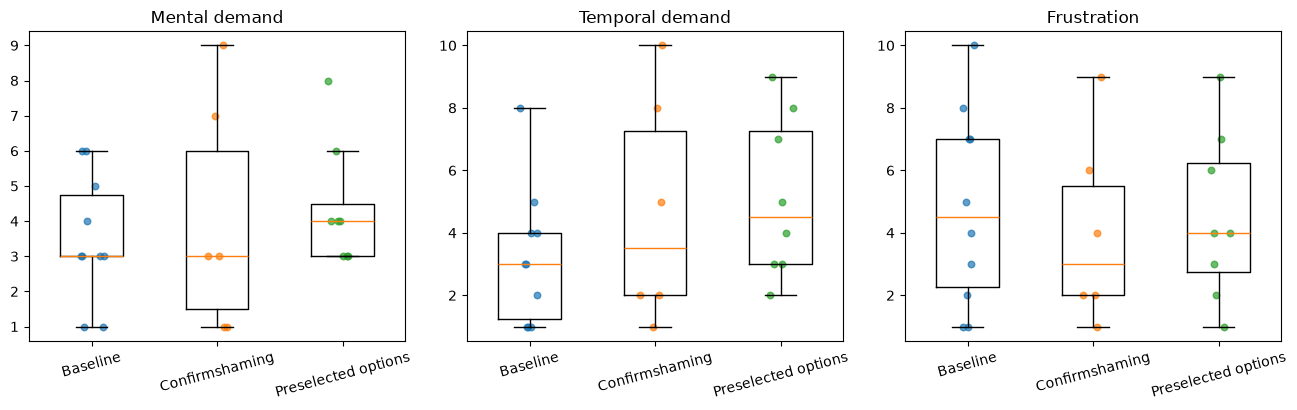

In [56]:
colors = {lv: f"C{i}" for i, lv in enumerate(cond_order)}
fig, axes = plt.subplots(1, len(MEDIATORS), figsize=(4.4 * len(MEDIATORS), 4.2))
for ax, (col, label) in zip(np.atleast_1d(axes), MEDIATORS.items()):
    data = [df.loc[df["cond"] == lv, col].dropna() for lv in cond_order]
    ax.boxplot(data, widths=0.5, showfliers=False)
    for i, (lv, vals) in enumerate(zip(cond_order, data), start=1):
        ax.scatter(np.full(len(vals), i) + rng.normal(0, 0.05, len(vals)), vals,
                   alpha=0.7, s=22, color=colors[lv])
    ax.set_xticks(range(1, len(cond_order) + 1))
    ax.set_xticklabels(cond_order, rotation=15)
    ax.set_title(label)
plt.tight_layout()
plt.show()

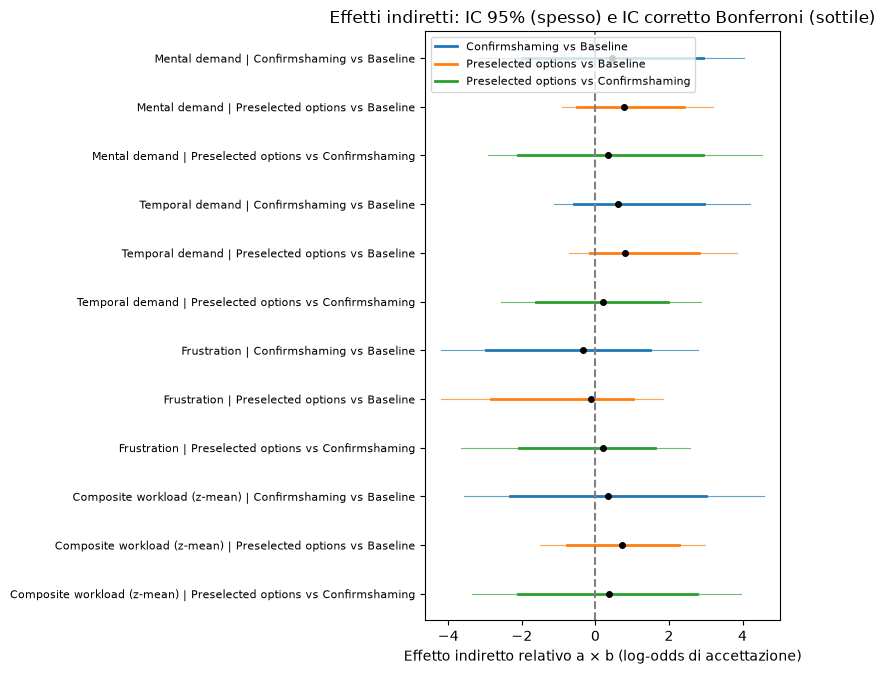

In [57]:
rows_plot = res_tab.reset_index()
fig, ax = plt.subplots(figsize=(8, 0.42 * len(rows_plot) + 1.8))
ys = np.arange(len(rows_plot))[::-1]
contrast_colors = {c: f"C{i}" for i, c in enumerate(CONTRASTS)}
for yv, (_, r) in zip(ys, rows_plot.iterrows()):
    col = contrast_colors[r["contrasto"]]
    ax.plot([r["ci_lo"], r["ci_hi"]], [yv, yv], lw=2, color=col)
    ax.plot([r["ci_lo_adj"], r["ci_hi_adj"]], [yv, yv], lw=0.8, color=col, alpha=0.7)
    ax.plot(r["indirect_ab"], yv, "o", color="k", ms=4)
ax.axvline(0, color="grey", ls="--")
ax.set_yticks(ys)
ax.set_yticklabels([f"{m} | {c}" for m, c in zip(rows_plot["mediatore"], rows_plot["contrasto"])], fontsize=8)
ax.set_xlabel("Effetto indiretto relativo a × b (log-odds di accettazione)")
ax.set_title("Effetti indiretti: IC 95% (spesso) e IC corretto Bonferroni (sottile)")
handles = [plt.Line2D([0], [0], color=c, lw=2) for c in contrast_colors.values()]
ax.legend(handles, list(contrast_colors), loc="best", fontsize=8)
plt.tight_layout()
plt.show()

## 9. Sintesi dei risultati e limiti

In [58]:
print("Effetti totali sull'accettazione (Firth, log-odds):")
for k in TREAT_KEYS:
    print(f"- {LABELS[k]} vs {REFERENCE_LABEL}: c = {c_total[k]:.3f} (OR = {np.exp(c_total[k]):.2f})")
print()
for (mediatore, contrasto), r in res_tab.iterrows():
    verdetto = ("IC95% esclude lo zero → evidenza di mediazione"
                if r["mediazione_ic95"] else
                "IC95% include lo zero → inconcludente")
    print(f"- {mediatore} | {contrasto} (n = {int(r['n'])}, gruppi {r['n_gruppi']}): "
          f"a = {r['a']:.2f}, b = {r['b_logodds']:.2f}, c' = {r['c_prime']:.2f}, "
          f"a×b = {r['indirect_ab']:.3f} [{r['ci_lo']:.3f}, {r['ci_hi']:.3f}] → {verdetto}")

Effetti totali sull'accettazione (Firth, log-odds):
- Confirmshaming vs Baseline: c = 2.579 (OR = 13.18)
- Preselected options vs Baseline: c = 2.480 (OR = 11.94)

- Mental demand | Confirmshaming vs Baseline (n = 24, gruppi 10/6/8): a = 0.23, b = 1.94, c' = 2.43, a×b = 0.449 [-1.984, 2.939] → IC95% include lo zero → inconcludente
- Mental demand | Preselected options vs Baseline (n = 24, gruppi 10/6/8): a = 0.40, b = 1.94, c' = 2.77, a×b = 0.785 [-0.489, 2.408] → IC95% include lo zero → inconcludente
- Mental demand | Preselected options vs Confirmshaming (n = 24, gruppi 10/6/8): a = 0.17, b = 1.94, c' = 0.34, a×b = 0.336 [-2.103, 2.923] → IC95% include lo zero → inconcludente
- Temporal demand | Confirmshaming vs Baseline (n = 24, gruppi 10/6/8): a = 0.53, b = 1.17, c' = 2.01, a×b = 0.622 [-0.580, 2.946] → IC95% include lo zero → inconcludente
- Temporal demand | Preselected options vs Baseline (n = 24, gruppi 10/6/8): a = 0.70, b = 1.17, c' = 2.10, a×b = 0.816 [-0.156, 2.822] → IC95

### Come riportare i risultati
Per ogni mediatore e ogni contrasto riporta *a*, *b*, *c′*, l'effetto indiretto relativo con IC bootstrap al 95% (numero di ricampionamenti e seme), e dichiara che l'analisi è **esplorativa**. Evita di esprimere una «quota di mediazione»: con esito logistico non è direttamente interpretabile.

### Limiti da dichiarare
- **Potere statistico molto basso**: con 3 gruppi e circa 25 casi con NASA-TLX restano in media ~8 osservazioni per gruppo; un IC che include lo zero è inconcludente, non prova l'assenza di mediazione.
- **Dati mancanti** sul NASA-TLX: la complete-case analysis è valida solo se la mancanza non dipende da condizione o Y (sezione 3).
- **Significato di `acceptance` nelle tre condizioni**: in v3 (preselected options) accettare può significare lasciare spuntata un'opzione, in v2 cliccare un pulsante; verifica che la definizione sia comparabile (sezione 2) e dichiara eventuali differenze.
- **Ordine temporale**: il NASA-TLX è misurato *dopo* l'esposizione e la decisione, quindi la frustrazione potrebbe essere una conseguenza della scelta e non una causa.
- **Confondenti** M–Y non misurati: X è randomizzato, M no, quindi la mediazione resta un'ipotesi causale con assunzioni forti.
- **Test multipli**: 3 mediatori × 2 trattamenti; l'IC corretto usa Bonferroni su questi 6 test. Il confronto v3 vs v2 e l'indice composito sono analisi aggiuntive.
- Non sono incluse covariate (età, dispositivo, frequenza d'acquisto) per non sovraparametrizzare il modello.